In [11]:
!pip install GEOparse pandas numpy matplotlib seaborn

In [12]:
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download GEO dataset
gse = GEOparse.get_GEO(
    geo="GSE66625",
    destdir="."
)

print("Dataset downloaded successfully")
print("GEO accession:", gse.name)
print("Number of samples:", len(gse.gsms))

27-Nov-2026 05:18:13 DEBUG utils - Directory . already exists. Skipping.
DEBUG:GEOparse:Directory . already exists. Skipping.
27-Nov-2026 05:18:13 INFO GEOparse - File already exist: using local version.
INFO:GEOparse:File already exist: using local version.
27-Nov-2026 05:18:13 INFO GEOparse - Parsing ./GSE66625_family.soft.gz: 
INFO:GEOparse:Parsing ./GSE66625_family.soft.gz: 
27-Nov-2026 05:18:13 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
27-Nov-2026 05:18:13 DEBUG GEOparse - SERIES: GSE66625
DEBUG:GEOparse:SERIES: GSE66625
27-Nov-2026 05:18:13 DEBUG GEOparse - PLATFORM: GPL16951
DEBUG:GEOparse:PLATFORM: GPL16951
27-Nov-2026 05:18:13 DEBUG GEOparse - SAMPLE: GSM1626567
DEBUG:GEOparse:SAMPLE: GSM1626567
27-Nov-2026 05:18:13 DEBUG GEOparse - SAMPLE: GSM1626568
DEBUG:GEOparse:SAMPLE: GSM1626568
27-Nov-2026 05:18:13 DEBUG GEOparse - SAMPLE: GSM1626569
DEBUG:GEOparse:SAMPLE: GSM1626569
27-Nov-2026 05:18:13 DEBUG GEOparse - SAMPLE: GSM1626570
DEBUG:GEOparse:SAMP

Dataset downloaded successfully
GEO accession: GSE66625
Number of samples: 6


In [13]:
# Define sample groups
control_samples = [
    "GSM1626567",
    "GSM1626568",
    "GSM1626569"
]

drug_samples = [
    "GSM1626570",
    "GSM1626571",
    "GSM1626572"
]

sample_ids = control_samples + drug_samples

# Combine expression values from all six samples
expression_data = {}

for sample_id in sample_ids:

    sample = gse.gsms[sample_id]

    table = sample.table[["ID_REF", "VALUE"]].copy()

    table["VALUE"] = pd.to_numeric(
        table["VALUE"], errors="coerce"
    )

    expression_data[sample_id] = (
        table.drop_duplicates("ID_REF")
             .set_index("ID_REF")["VALUE"]
    )

# Create expression matrix
expression_matrix = pd.DataFrame(expression_data)

print("Expression matrix dimensions:")
print(expression_matrix.shape)

expression_matrix.head()

Expression matrix dimensions:
(31741, 6)


,GSM1626567,GSM1626568,GSM1626569,GSM1626570,GSM1626571,GSM1626572
ID_REF,,,,,,
PH_hs_0000002,249.075851,250.485489,363.787689,343.359619,336.227753,291.783722
PH_hs_0000003,205.121277,218.508621,215.953644,267.757507,239.595367,247.867279
PH_hs_0000004,2737.392330,1509.308230,1462.397460,1682.147220,1571.269040,2719.841060
PH_hs_0000005,30.524000,19.186123,46.379307,66.151856,90.013725,69.968544
PH_hs_0000006,1073.223880,689.634521,1324.708980,1173.407840,1290.638060,1466.362060


In [14]:
sample_statistics = pd.DataFrame({
    "Mean": expression_matrix.mean(),
    "Median": expression_matrix.median(),
    "Standard_Deviation": expression_matrix.std(),
    "Minimum": expression_matrix.min(),
    "Maximum": expression_matrix.max()
})

sample_statistics

,Mean,Median,Standard_Deviation,Minimum,Maximum
GSM1626567,3710.397853,438.935120,13633.677630,-20.756321,306181.969
GSM1626568,3756.065218,376.261169,15098.435189,-28.779182,381943.469
GSM1626569,3591.262640,394.224121,15838.090730,5.797413,595388.562
GSM1626570,3671.114167,420.536804,16159.483819,0.000000,619499.500
GSM1626571,3570.114629,427.565216,15064.304760,1.323731,439413.938
GSM1626572,3670.091355,475.637238,13959.057598,-1.488692,323216.719


In [15]:
sample_statistics.to_csv(
    "sample_statistics.csv"
)

print("Statistics saved successfully")

Statistics saved successfully


In [16]:
control_mean = expression_matrix[
    control_samples
].mean(axis=1)

drug_mean = expression_matrix[
    drug_samples
].mean(axis=1)

comparison = pd.DataFrame({
    "Control_Mean": control_mean,
    "Drug_Mean": drug_mean
})

comparison["Mean_Difference"] = (
    comparison["Drug_Mean"] -
    comparison["Control_Mean"]
)

comparison.head()

,Control_Mean,Drug_Mean,Mean_Difference
ID_REF,,,
PH_hs_0000002,287.783010,323.790365,36.007355
PH_hs_0000003,213.194514,251.740051,38.545537
PH_hs_0000004,1903.032673,1991.085773,88.053100
PH_hs_0000005,32.029810,75.378042,43.348232
PH_hs_0000006,1029.189127,1310.135987,280.946860


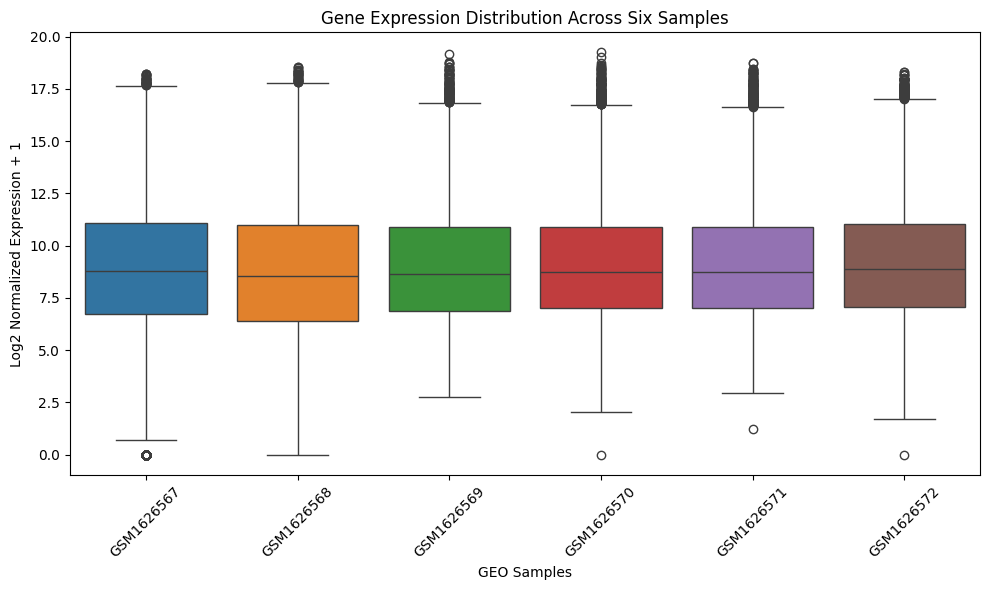

In [17]:
# Log2 transformation for visualization only
log_expression = np.log2(
    expression_matrix.clip(lower=0) + 1
)

plt.figure(figsize=(10, 6))

sns.boxplot(data=log_expression)

plt.title("Gene Expression Distribution Across Six Samples")
plt.xlabel("GEO Samples")
plt.ylabel("Log2 Normalized Expression + 1")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "expression_boxplot.png",
    dpi=300
)

plt.show()

In [18]:
# Save expression matrix and comparison
expression_matrix.to_csv("expression_matrix.csv")

comparison.to_csv("control_vs_drug_comparison.csv")

print("All analysis files saved!")

All analysis files saved!


In [19]:
print("Expression matrix shape:")
print(expression_matrix.shape)

print("\nMissing values:")
print(expression_matrix.isnull().sum())

print("\nSample statistics:")
display(sample_statistics)

print("\nControl and drug group means:")
print(expression_matrix[control_samples].mean().mean())
print(expression_matrix[drug_samples].mean().mean())

Expression matrix shape:
(31741, 6)

Missing values:
GSM1626567    0
GSM1626568    0
GSM1626569    0
GSM1626570    0
GSM1626571    0
GSM1626572    0
dtype: int64

Sample statistics:


,Mean,Median,Standard_Deviation,Minimum,Maximum
GSM1626567,3710.397853,438.935120,13633.677630,-20.756321,306181.969
GSM1626568,3756.065218,376.261169,15098.435189,-28.779182,381943.469
GSM1626569,3591.262640,394.224121,15838.090730,5.797413,595388.562
GSM1626570,3671.114167,420.536804,16159.483819,0.000000,619499.500
GSM1626571,3570.114629,427.565216,15064.304760,1.323731,439413.938
GSM1626572,3670.091355,475.637238,13959.057598,-1.488692,323216.719



Control and drug group means:
3685.9085702941834
3637.106716942934


In [20]:
sample_statistics.to_csv("sample_statistics.csv")

comparison.to_csv("control_vs_drug_comparison.csv")

expression_matrix.to_csv("expression_matrix.csv")

print("Task 2 results saved successfully!")

Task 2 results saved successfully!
